## Pré Processamento de imagens

Até o momento, trabalhamos com dados tabulares. No entanto, existe um universo ainda maior de dados não estruturados, como imagens e textos.Para algoritmos de Machine Learning, uma imagem não possui cor ou forma intrínseca; ela é interpretada como uma grade de intensidades luminosas.

**Imagens em Escala de Cinza (Grayscale)** São representadas por matrizes bidimensionais (2D). Cada elemento da matriz (pixel) carrega um valor de intensidade. Em imagens padrão de 8 bits, esse valor varia de $0$ (preto absoluto) a $255$ (branco absoluto).Ponto importante: Note que a orientação do sistema de coordenadas difere do plano cartesiano convencional. Na computação gráfica, a origem $(0,0)$ localiza-se geralmente no canto superior esquerdo da imagem.

![texto do link](https://upload.wikimedia.org/wikipedia/commons/thumb/8/89/Representa%C3%A7%C3%A3o_de_uma_imagem_digital_-_Matriz_de_pixel.jpg/960px-Representa%C3%A7%C3%A3o_de_uma_imagem_digital_-_Matriz_de_pixel.jpg)

**Imagens Coloridas (RGB)** As imagens coloridas adicionam uma dimensão de profundidade, sendo representadas por arrays tridimensionais (3D) ou tensores. O formato matemático padrão é $(H, W, C)$, onde:$H$ = Height (Altura/Linhas)$W$ = Width (Largura/Colunas)$C$ = Channels (Canais de cor: Red, Green, Blue)Nota técnica: Podem existir mais canais em imagens multiespectrais ou canais de transparência (Alpha). Imagens baseadas em matrizes de pixels também são conhecidas como imagens Raster.

![texto do link](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcThN5VK56EDnZnC8KF0yHmKCiZEsMOnrcfvjw&s)

Existem inúmeros pacotes para manipulação de imagens em Python. Cada um possui suas particularidades e nichos de aplicação:

**OpenCV (cv2)**: Focado em performance e visão computacional em tempo real. É amplamente utilizado na indústria para processamento pesado de vídeo e fluxos de alta velocidade. Diferente de quase todas as outras bibliotecas (que usam RGB), o OpenCV carrega imagens no padrão BGR (Blue-Green-Red)

**Pillow (PIL)**: Frequentemente a escolha padrão para quem trabalha com `PyTorch`. É leve e intuitiva para operações básicas de edição.

**Scikit-Image (skimage)**: Para quem já está habituado ao ecossistema do scikit-learn, o caminho mais natural é o emprego do skimage. Ele é construído sobre o `NumPy` e o `SciPy`, tratando as imagens diretamente como arrays multidimensionais, o que facilita a integração com algoritmos de Machine Learning clássico.

--- Inspeção da Estrutura de Dados ---
Tipo do objeto: <class 'numpy.ndarray'>
Dimensões (H, W, C): (500, 900, 3)
Valor máximo do pixel: 255 

--- Pós Conversão para Grayscale ---
Novas Dimensões: (500, 900)
Novo valor máximo: 0.94 (Convertido para float)



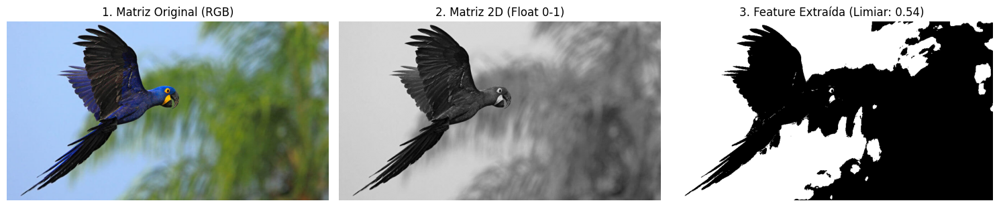

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, color, filters

# CAREEGAR A IMAGEM
# Substitua o caminho, pode ser o link
caminho_img = "https://s5.static.brasilescola.uol.com.br/img/2019/06/arara-azul.jpg"
imagem_passaro = io.imread(caminho_img)

# a imagem é apenas um array NumPy nativo em RGB
print("--- Inspeção da Estrutura de Dados ---")
print(f"Tipo do objeto: {type(imagem_passaro)}")
print(f"Dimensões (H, W, C): {imagem_passaro.shape}")
print(f"Valor máximo do pixel: {imagem_passaro.max()} \n") # (Geralmente 255 em uint8)

# Pré-processamento: Redução de Dimensionalidade (RGB para Grayscale)
# O skimage não apenas converte a cor, mas já mapeia os valores para o intervalo float [0.0, 1.0]
imagem_cinza = color.rgb2gray(imagem_passaro)

print("--- Pós Conversão para Grayscale ---")
print(f"Novas Dimensões: {imagem_cinza.shape}") # O canal de cor (C) desaparece
print(f"Novo valor máximo: {imagem_cinza.max():.2f} (Convertido para float)\n")

#Engenharia de Features: Binarização (Thresholding)
# Vamos usar o algoritmo de Otsu para encontrar matematicamente o ponto de corte ideal
# que separa os pixels claros (Ceu)  dos escuros (passo e as plantas),como  aplicar o algoritmo de clusterização K-Means com K=2.
limiar_otsu = filters.threshold_otsu(imagem_cinza)

# Criando uma máscara booleana (exatamente como faríamos um filtro em um DataFrame pandas)
mascara = imagem_cinza > limiar_otsu

#Visualização
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(imagem_passaro)
axes[0].set_title("1. Matriz Original (RGB)")
axes[0].axis('off')

axes[1].imshow(imagem_cinza, cmap='gray')
axes[1].set_title("2. Matriz 2D (Float 0-1)")
axes[1].axis('off')

axes[2].imshow(mascara, cmap='gray')
axes[2].set_title(f"3. Feature Extraída (Limiar: {limiar_otsu:.2f})")
axes[2].axis('off')

plt.tight_layout()
plt.show()

Vamos fazer uma contagem de plantas com base em uma imagem de drone: https://drive.google.com/file/d/1Dqp2cJQwvUcGP1ztkJN6jzydBTZdXRwg/view

--- Inspeção da Estrutura de Dados ---
Tipo do objeto: <class 'numpy.ndarray'>
Dimensões do Tensor (H, W, C): (741, 1230, 4)

--- Pós Extração do Canal Verde ---
Novas Dimensões (Matriz 2D): (741, 1230)
Tipo de dado preservado: uint8


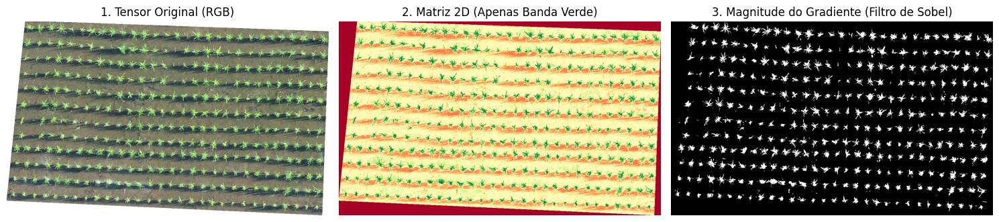

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, color, feature, transform, draw

# CARREGAR A IMAGEM
caminho_img = "/content/test_img.tif"
imagem_passaro = io.imread(caminho_img)

print("--- Inspeção da Estrutura de Dados ---")
print(f"Tipo do objeto: {type(imagem_passaro)}")
print(f"Dimensões do Tensor (H, W, C): {imagem_passaro.shape}")

# Operação de Slicing (Fatiamento de Tensor)
# O array possui 3 dimensões (Altura, Largura, Canais de Cor).
# Os canais são indexados como: 0 = Red, 1 = Green, 2 = Blue.
# Ao usar [:, :, 1], selecionamos todas as linhas e colunas, mas apenas a fatia de profundidade 1(verde).
canal_verde = imagem_passaro[:, :, 1]

print("\n--- Pós Extração do Canal Verde ---")
print(f"Novas Dimensões (Matriz 2D): {canal_verde.shape}")
print(f"Tipo de dado preservado: {canal_verde.dtype}")

# remoção das bordas
canal_verde = np.where(canal_verde == 255,0,canal_verde)


limiar_otsu = filters.threshold_otsu(canal_verde)

# Criando uma máscara booleana (exatamente como faríamos um filtro em um DataFrame pandas)
mascara = canal_verde > 162

# Visualização
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(imagem_passaro)
axes[0].set_title("1. Tensor Original (RGB)")
axes[0].axis('off')


axes[1].imshow(canal_verde, cmap='RdYlGn')
axes[1].set_title("2. Matriz 2D (Apenas Banda Verde)")
axes[1].axis('off')


axes[2].imshow(mascara, cmap='gray')
axes[2].set_title("3. Magnitude do Gradiente (Filtro de Sobel)")
axes[2].axis('off')

plt.tight_layout()
plt.show()

--- Inspeção Pré-Morfologia ---
Tipo de dado da máscara: uint8

--- Resultado dos Componentes Conexos ---
Total de estruturas independentes encontradas: 345


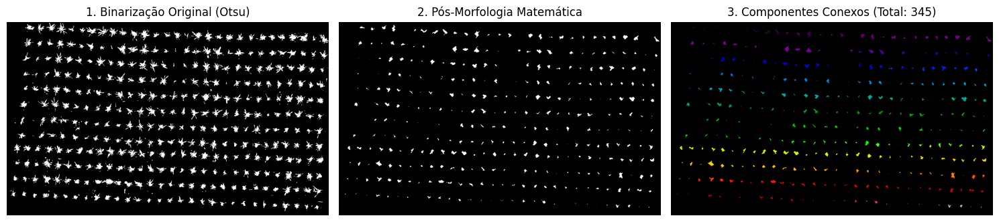

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 'mascara' é a sua matriz booleana (True/False) do passo do Otsu.
# IMPORTANTE: O OpenCV não trabalha bem com booleanos puros.
# Precisamos converter o tensor para inteiros de 8 bits (0 para preto, 255 para branco).
binary = (mascara * 255).astype(np.uint8)

print("--- Inspeção Pré-Morfologia ---")
print(f"Tipo de dado da máscara: {binary.dtype}")

#  Definição do Elemento Estruturante (Kernel)
# Uma matriz 3x3 em formato de elipse. Atua como o "pincel" das operações matemáticas.
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))

# Operações Morfológicas (Filtros Espaciais)
# A sequência de dilatações e erosões altera a topologia da imagem para unir objetos
# fragmentados e apagar ruídos isolados.
imagem_morfol = cv2.dilate(binary, kernel, iterations=3)
imagem_morfol = cv2.erode(imagem_morfol, kernel, iterations=6)
imagem_morfol = cv2.dilate(imagem_morfol, kernel, iterations=4)
imagem_morfol = cv2.erode(imagem_morfol, kernel, iterations=6)

# Análise de Componentes Conexos
# O algoritmo varre a matriz e atribui um "ID" único para cada grupo de pixels brancos que se tocam.
num_labels, labels_im = cv2.connectedComponents(imagem_morfol)

# A contagem real de objetos ignora o ID 0, que é reservado para o fundo (background) preto.
total_objetos = num_labels - 1

print("\n--- Resultado dos Componentes Conexos ---")
print(f"Total de estruturas independentes encontradas: {total_objetos}")

# Visualização
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(binary, cmap='gray')
axes[0].set_title("1. Binarização Original (Otsu)")
axes[0].axis('off')

axes[1].imshow(imagem_morfol, cmap='gray')
axes[1].set_title("2. Pós-Morfologia Matemática")
axes[1].axis('off')

# Para visualizar os labels, usamos um mapa de cores randômico ou sequencial (como 'nipy_spectral')
# Como o fundo é 0, ele ficará com a primeira cor do mapa (geralmente escuro).
axes[2].imshow(labels_im, cmap='nipy_spectral')
axes[2].set_title(f"3. Componentes Conexos (Total: {total_objetos})")
axes[2].axis('off')

plt.tight_layout()
plt.show()

--- Processamento de Bounding Boxes ---
Total de objetos emoldurados: 345


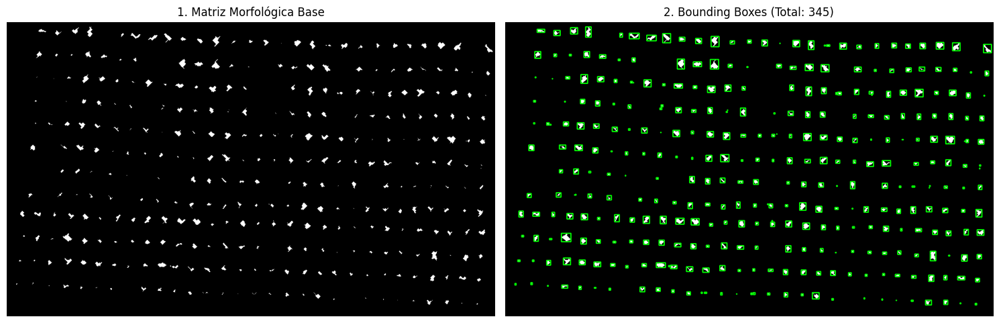

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Executa o algoritmo de grafos novamente
num_labels, labels_im, stats, centroids = cv2.connectedComponentsWithStats(imagem_morfol, connectivity=8)

# Cria uma cópia colorida (RGB) para que o retângulo possa ser colorido
imagem_anotada = cv2.cvtColor(imagem_morfol, cv2.COLOR_GRAY2RGB)

total_objetos = 0

# O loop começa no 1 para ignorar o background (ID 0)
for i in range(1, num_labels):

    # Extração das propriedades espaciais usando as constantes do OpenCV
    #
    x = stats[i, cv2.CC_STAT_LEFT]
    y = stats[i, cv2.CC_STAT_TOP]
    largura = stats[i, cv2.CC_STAT_WIDTH]
    altura = stats[i, cv2.CC_STAT_HEIGHT]

    # O OpenCV exige dois pontos diagonais para desenhar um retângulo:
    # Ponto 1: Canto superior esquerdo (x, y)
    # Ponto 2: Canto inferior direito (x + largura, y + altura)
    ponto_superior_esquerdo = (x, y)
    ponto_inferior_direito = (x + largura, y + altura)

    # cv2.rectangle(imagem, pt1, pt2, cor_RGB, espessura)
    cv2.rectangle(
        imagem_anotada,
        ponto_superior_esquerdo,
        ponto_inferior_direito,
        (0, 255, 0),  # Cor: Verde
        2             # Espessura da linha
    )

    total_objetos += 1

print(f" Processamento de Bounding Boxes")
print(f"Total de objetos emoldurados: {total_objetos}")

# Visualização
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# Mostramos a imagem binária limpa
axes[0].imshow(imagem_morfol, cmap='gray')
axes[0].set_title("1. Matriz Morfológica Base")
axes[0].axis('off')

# Mostramos a imagem com as Bounding Boxes
axes[1].imshow(imagem_anotada)
axes[1].set_title(f"2. Bounding Boxes (Total: {total_objetos})")
axes[1].axis('off')

plt.tight_layout()
plt.show()

Existem inúmeras formas de extrairmos características (features) de imagens. Dentre elas, podemos destacar o uso do algoritmo K-Means.No processamento de imagens, o K-Means é frequentemente utilizado para a Quantização de Cores ou Segmentação. Em vez de tratar a imagem como uma estrutura espacial, nós a reorganizamos como uma lista de observações (pixels), onde cada pixel é um ponto em um espaço tridimensional de cores (R, G, B).O objetivo é agrupar pixels com cores semelhantes em $K$ clusters. O centroide de cada cluster representará a "cor dominante" daquela região da imagem. Assim podemos transformar uma imagem que continha milhoes de cores em uma com poucas cores(K)

Dimensões da Imagem Original: 1654x2480 pixels com 3 canais coloridos
Novo formato para o sklearn: (4101920, 3)
Iniciando K-Means com K=3. Isso pode demorar um pouco...


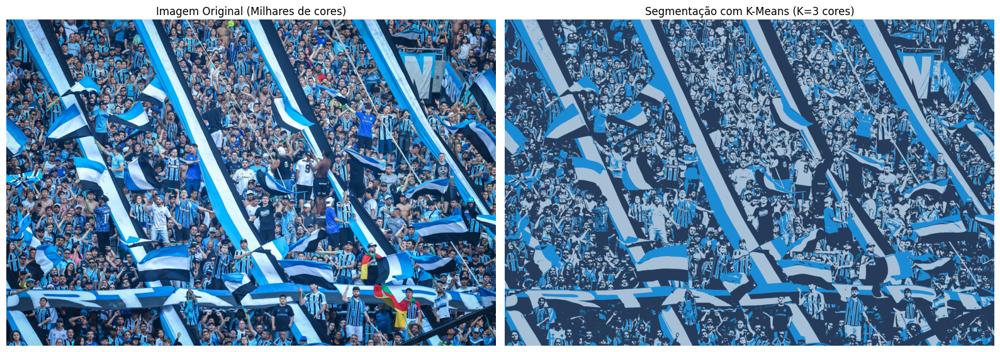


--- Centróides de Cores Encontrados (RGB 0-1) ---
Segmento 0: R=0.66, G=0.76, B=0.84
Segmento 1: R=0.15, G=0.23, B=0.35
Segmento 2: R=0.10, G=0.55, B=0.84


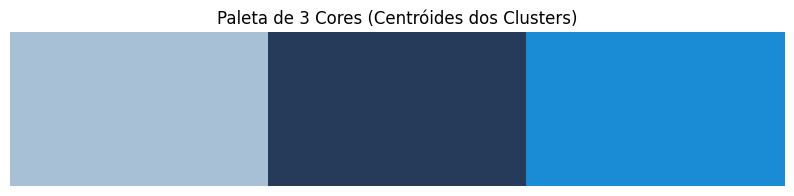

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, color
from sklearn.cluster import KMeans
from sklearn.utils import shuffle

#Carregamento
# Substitua o caminho, pode ser o link
caminho_img = "https://s2-ge.glbimg.com/qGpFzQ3ELZLmbNdROhfwhk8dCo8=/2480x0/filters:format(jpeg)/https://i.s3.glbimg.com/v1/AUTH_bc8228b6673f488aa253bbcb03c80ec5/internal_photos/bs/2024/L/1/13c9IsTGG1ebfpUFMAnA/54094929112-a1c984cb95-o.jpg"
imagem_time = io.imread(caminho_img)

H, W, C = imagem_time.shape
print(f"Dimensões da Imagem Original: {H}x{W} pixels com {C} canais coloridos")

# Transformação de Tensor para Matriz de Features
# Convertemos uint8 (0-255) para float (0-1) para estabilidade do K-Means (Escalonamento (MinMaxScaler para Imagens))
# e fazemos o reshape para (N, 3)
amostra_pixels = np.array(imagem_time, dtype=np.float64) / 255.0
matriz_features = np.reshape(amostra_pixels, (H * W, C))

print(f"Novo formato para o sklearn: {matriz_features.shape}")

#  Treinamento do K-Means
# Definimos K=4. Queremos que a imagem inteira seja representada por apenas 4 cores.
K = 3
print(f"Iniciando K-Means com K={K}. Isso pode demorar um pouco...")

# DICA: Para imagens grandes, use uma subamostra para treinar
# e aplique no resto, para ser mais rápido.
matriz_treino = shuffle(matriz_features, random_state=42)[:10000] # Treina só com 10k pixels

# Nota: O K-Means usa a distância euclidiana entre as cores R,G,B para agrupar.
kmeans = KMeans(n_clusters=K, random_state=42, n_init='auto').fit(matriz_treino)

#  Predição e Reconstrução da Imagem
# Agora que temos os 3 centros de cores (centróides), dizemos a qual centro cada pixel original pertence.
rotulos = kmeans.predict(matriz_features)# retorna a que classe pertence cada pixel
cores_centroides = kmeans.cluster_centers_

# Reconstruímos a imagem substituindo cada pixel pela cor do centróide do seu grupo
imagem_quantizada_matriz = cores_centroides[rotulos]
imagem_quantizada = np.reshape(imagem_quantizada_matriz, (H, W, C))

#Visualização Comparativa
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(imagem_time)
axes[0].set_title(f"Imagem Original (Milhares de cores)")
axes[0].axis('off')

axes[1].imshow(imagem_quantizada)
axes[1].set_title(f"Segmentação com K-Means (K={K} cores)")
axes[1].axis('off')

plt.tight_layout()
plt.show()

#resultado
print("\n--- Centróides de Cores Encontrados (RGB 0-1) ---")
for i, cor in enumerate(cores_centroides):
    print(f"Segmento {i}: R={cor[0]:.2f}, G={cor[1]:.2f}, B={cor[2]:.2f}")

paleta_plot = cores_centroides[np.newaxis, :, :]

plt.figure(figsize=(10, 2))
plt.imshow(paleta_plot, aspect='auto')
plt.title(f"Paleta de {K} Cores (Centróides dos Clusters)")
plt.axis('off')
plt.show()

Onde antes existia um degradê suave (transições sutis de tons), após o processamento com K-Means surgem blocos sólidos de cor com bordas nítidas e definidas.

Muitas vezes, ao utilizarmos modelos de Machine Learning (especialmente Redes Neurais Convolucionais), precisamos alimentar o algoritmo com dados em um formato padronizado. Um valor extremamente comum na indústria é o $224 \times 224$ pixels

Dimensões da Imagem Original: 2480x1654 pixels (Proporção Retangular)


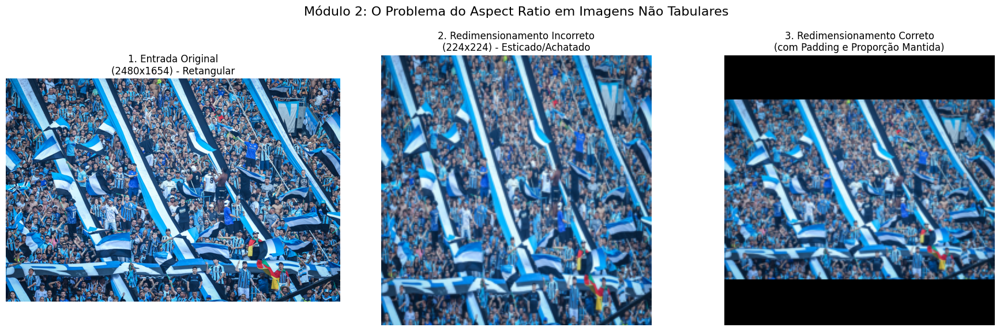

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, transform

# Função
def redimensionar_com_padding(imagem, tamanho_alvo):

    #Redimensiona mantendo a proporção (aspect ratio) e preenche o resto
    #com zeros (padding).

    h_orig, w_orig = imagem.shape[:2]
    h_alvo, w_alvo = tamanho_alvo

    # Qual lado é o gargalo? Calcula a escala baseada no maior lado
    escala = min(w_alvo / w_orig, h_alvo / h_orig)

    # Novas dimensões proporcionais
    novo_w = int(w_orig * escala)
    novo_h = int(h_orig * escala)

    # Redimensionamento matemático
    imagem_redimensionada = transform.resize(
        imagem, (novo_h, novo_w),
        anti_aliasing=True, # remover o serrilhado (para o ML não achar que tem uma textura aspera)
        preserve_range=True # preserava valores entre 0 _ 255
    ).astype(imagem.dtype)

    # Padding (Preenchimento)
    delta_w = w_alvo - novo_w
    delta_h = h_alvo - novo_h

    # Divide o espaço vazio por 2 para centralizar a imagem na nova matriz
    top, bottom = delta_h // 2, delta_h - (delta_h // 2)
    left, right = delta_w // 2, delta_w - (delta_w // 2)

    # Manipulação de Tensor com NumPy (Padding nas dimensões H e W)
    imagem_com_padding = np.pad(
        imagem_redimensionada,
        pad_width=((top, bottom), (left, right), (0, 0)),
        mode='constant',
        constant_values=0 # Preenche com 0 (preto)
    )

    return imagem_com_padding

# Execução da Demonstração

# URL da imagem
url_imagem = "https://s2-ge.glbimg.com/qGpFzQ3ELZLmbNdROhfwhk8dCo8=/2480x0/filters:format(jpeg)/https://i.s3.glbimg.com/v1/AUTH_bc8228b6673f488aa253bbcb03c80ec5/internal_photos/bs/2024/L/1/13c9IsTGG1ebfpUFMAnA/54094929112-a1c984cb95-o.jpg"
# Carregando a imagem diretamente da web usando scikit-image (RGB nativo)
imagem_original = io.imread(url_imagem)

# Inspeção inicial
h_orig, w_orig = imagem_original.shape[:2]
print(f"Dimensões da Imagem Original: {w_orig}x{h_orig} pixels (Proporção Retangular)")

# Tamanho padrão de muitas CNNs
tamanho_alvo_rede = (224, 224) # Quadrado

#  O Jeito Errado (Distorção)
# Forçamos a imagem a ser 224x224, ignorando sua proporção original
imagem_esticada = transform.resize(
    imagem_original, tamanho_alvo_rede, anti_aliasing=True
)

#  O Jeito Certo (Aspect Ratio Preservado com Padding)
imagem_correta_padding = redimensionar_com_padding(imagem_original, tamanho_alvo_rede)
# Normalizando apenas para visualização no matplotlib, já que skimage.transform pode mudar o range
imagem_correta_padding = imagem_correta_padding.astype(np.float32) / 255.0

# Visualização Didática
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Título Principal da Aula
fig.suptitle("Módulo 2: O Problema do Aspect Ratio em Imagens Não Tabulares", fontsize=16)

axes[0].imshow(imagem_original)
axes[0].set_title(f"1. Entrada Original\n({w_orig}x{h_orig}) - Retangular")
axes[0].axis('off')

axes[1].imshow(imagem_esticada)
axes[1].set_title(f"2. Redimensionamento Incorreto\n({tamanho_alvo_rede[1]}x{tamanho_alvo_rede[0]}) - Esticado/Achatado")
axes[1].axis('off')

axes[2].imshow(imagem_correta_padding)
axes[2].set_title(f"3. Redimensionamento Correto\n(com Padding e Proporção Mantida)")
axes[2].axis('off')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

Um pixel em uint8 varia de $0$ a $255$. Se alimentarmos esses valores diretamente em modelos que utilizam Descida do Gradiente como Redes Neurais ou Regressão Logística, teremos problemas: Explosão de Gradientes: Valores altos ($255$) podem gerar pesos muito grandes, tornando o modelo instável.
Convergência Lenta: O modelo demora muito mais para encontrar o "mínimo global" se os dados não estiverem centralizados.
PAra estabilidade Numérica é necessarioo Escalonar para $[0, 1]$ ou $[-1, 1]$ garante que todas as características (canais R, G e B) tenham a mesma importância matemática durante o cálculo da função de custo.

1. Matriz Original (NumPy):
Shape: (512, 512, 3) | Tipo: uint8 | Range: [0, 255]

2. Pós-Escalonamento:
Shape: (512, 512, 3) | Tipo: float32 | Range: [0.0, 1.0]

3. Pós-Padronização (Z-Score):
Shape: (512, 512, 3) | Média Aproximada: -0.00

4. Pós-Transposição Espacial:
Novo Shape: (3, 512, 512)

5. Tensor Final Pronto para a GPU:
Shape do Tensor: torch.Size([1, 3, 512, 512]) | Formato: (Batch, Channels, Height, Width)


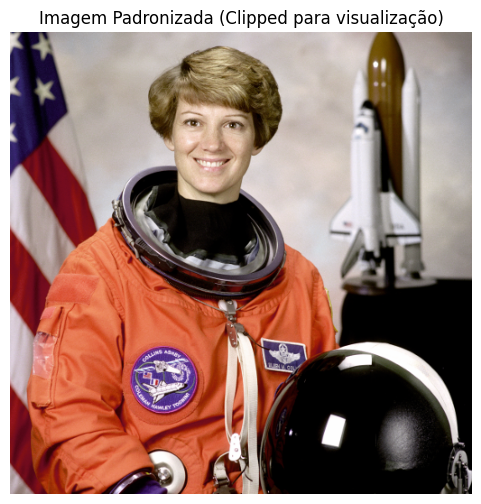

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from skimage import data

#  Carregando uma imagem padrão do skimage (ex: astronauta)
imagem_raw = data.astronaut()
print(" Matriz Original (NumPy):")
print(f"Shape: {imagem_raw.shape} | Tipo: {imagem_raw.dtype} | Range: [{imagem_raw.min()}, {imagem_raw.max()}]\n")

# Escalonamento (MinMaxScaler para Imagens)
# Convertendo de uint8 [0, 255] para float32 [0.0, 1.0]
imagem_float = imagem_raw.astype(np.float32) / 255.0
print("Pós-Escalonamento:")
print(f"Shape: {imagem_float.shape} | Tipo: {imagem_float.dtype} | Range: [{imagem_float.min():.1f}, {imagem_float.max():.1f}]\n")

# Padronização (Z-Score com constantes do ImageNet)
# Usamos arrays NumPy para aplicar a operação de forma vetorizada em cada canal
mean = np.array([0.485, 0.456, 0.406]) # valores do ImageNEt
std = np.array([0.229, 0.224, 0.225])# valores do ImageNEt

# O broadcasting subtrai a média do canal R do eixo R, G do G, e assim por diante.
imagem_padronizada = (imagem_float - mean) / std

print("Pós-Padronização (Z-Score):")
print(f"Shape: {imagem_padronizada.shape} | Média Aproximada: {imagem_padronizada.mean():.2f}\n")

# Transposição de Eixos (HWC para CHW)
# O shape atual é (512, 512, 3) -> Índices: (0, 1, 2)
# Queremos (3, 512, 512) -> Novos Índices: (2, 0, 1)
imagem_chw = np.transpose(imagem_padronizada, (2, 0, 1))

print("Pós-Transposição Espacial:")
print(f"Novo Shape: {imagem_chw.shape}\n")

# conversão Final para Tensor do PyTorch
# Adicionamos uma dimensão extra no início para simular o "Batch Size" (B, C, H, W)
# Redes neurais sempre esperam um lote de imagens, mesmo que seja um lote de 1.
tensor_pytorch = torch.from_numpy(imagem_chw).unsqueeze(0)

print("5. Tensor Final Pronto para a GPU:")
print(f"Shape do Tensor: {tensor_pytorch.shape} | Formato: (Batch, Channels, Height, Width)")

# Adicionando visualização da imagem padronizada
plt.figure(figsize=(6, 6))
# A imagem padronizada pode ter valores fora do range [0, 1], então clipamos para visualização
plt.imshow(imagem_raw)
plt.title("Imagem Padronizada (Clipped para visualização)")
plt.axis('off')
plt.show()

### Data Augmentation

Redes neurais profundas têm milhões de parâmetros. Se você fornecer a elas um dataset pequeno, elas não vão aprender a abstração do objeto; elas vão decorar os pixels.

Para isso existe a data Augmentation


* Flip (Espelhamento): Horizontal ou vertical.
* Rotation (Rotação): Girar a matriz em $N$ graus.
* Translation / Shift (Translação): Mover a imagem para os lados, para cima ou para baixo, preenchendo o vazio com padding.
* Zoom / Crop: Dar um "zoom" aleatório em uma parte da imagem, obrigando o modelo a reconhecer o objeto mesmo que ele esteja cortado ou muito perto.

* Brightness/Contrast (Brilho e Contraste): Simula fotos tiradas ao meio-dia vs. fim da tarde.

* Color Jittering: Alterações aleatórias na saturação e no matiz (HSV).

* Gaussian Noise (Ruído): Adicionar estática aleatória à matriz para simular sensores de baixa qualidade.

Muito importante estar atento a alguns aspectos, NÂO podemos fazer qualquer trasnformações nos dados, por exemplo: esta trabalhando em uma classificação de placas ou reconhecimento de numeros, fazer um flip horizontal trasnforma um "E" em um "3"



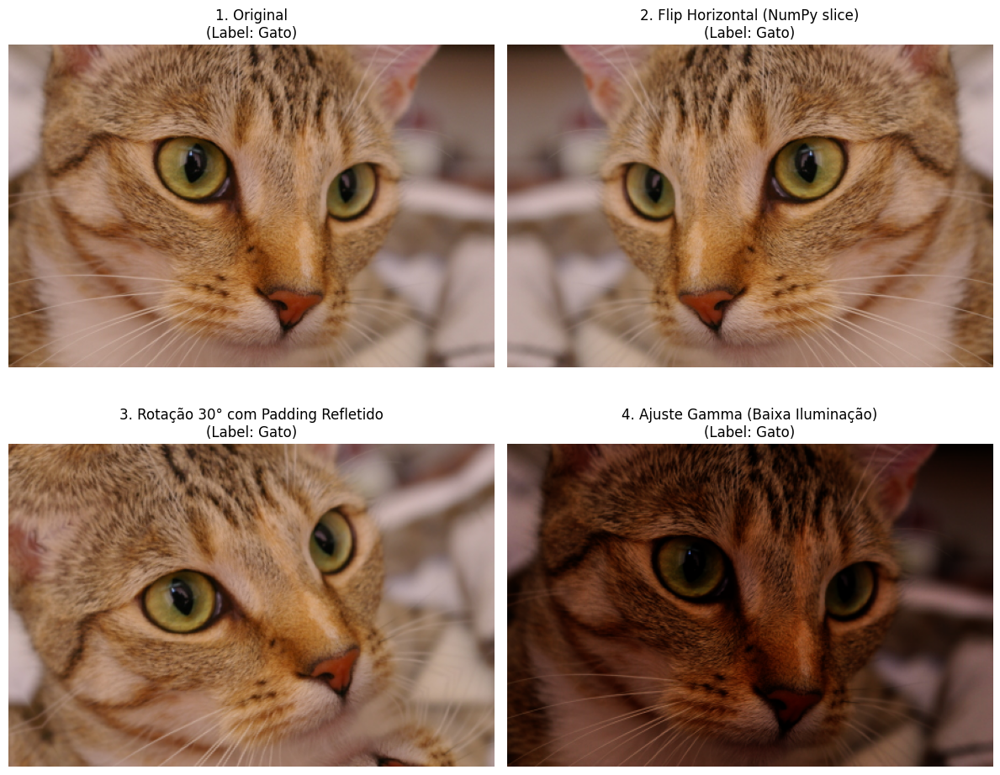

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, transform, exposure

#Carregando uma imagem clássica de teste do Skimage
imagem_original = data.chelsea() #  gato

# Transformação Geométrica: Flip Horizontal usando pura manipulação de matriz NumPy
# A sintaxe [:, ::-1, :] significa:
# Manter todas as linhas (Y), inverter a ordem das colunas (X), manter todos os canais (C)
imagem_flip = imagem_original[:, ::-1, :]

# Transformação Geométrica: Rotação
# mode='reflect' preenche os cantos vazios espelhando as bordas (melhor que preencher com preto)
imagem_rotacionada = transform.rotate(
    imagem_original,
    angle=30, # Rotacionar 30 graus
    mode='reflect',
    preserve_range=True
).astype(np.uint8)

# Transformação Fotométrica: Brilho (Correção Gamma)
# Gamma > 1 escurece a imagem (simulando pouca luz)
# Gamma < 1 clareia a imagem (simulando superexposição)
imagem_escura = exposure.adjust_gamma(imagem_original, gamma=2.5)

#Visualização
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].imshow(imagem_original)
axes[0, 0].set_title("1. Original\n(Label: Gato)")
axes[0, 0].axis('off')

axes[0, 1].imshow(imagem_flip)
axes[0, 1].set_title("2. Flip Horizontal (NumPy slice)\n(Label: Gato)")
axes[0, 1].axis('off')

axes[1, 0].imshow(imagem_rotacionada)
axes[1, 0].set_title("3. Rotação 30° com Padding Refletido\n(Label: Gato)")
axes[1, 0].axis('off')

axes[1, 1].imshow(imagem_escura)
axes[1, 1].set_title("4. Ajuste Gamma (Baixa Iluminação)\n(Label: Gato)")
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

Podemos estrair formas e Silhuetas que são otimos para ajudar a classificar imagens.
HOG (Histogram of Oriented Gradients) – A Silhueta: Ele ignora as cores e a textura interna, focando estritamente nas bordas e contornos geométricos. O HOG calcula para qual direção a intensidade da luz "muda" mais rápido (gradiente), criando um esboço matemático (como um desenho a lápis) da imagem.

Extraindo features HOG das imagens (poucos dados)...
Formato da Matriz Final: 10 amostras, 8100 features (Contornos)
Acurácia com HOG + SVM: 100.00%



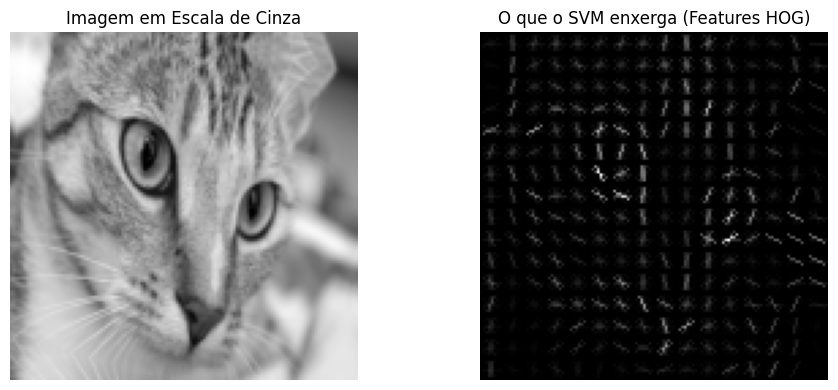

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, color, transform
from skimage.feature import hog
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

#  Simulando um Cenário Real de Poucos Dados
#  apenas 10 imagens no total
# 5 de Gatos e 5 de Não-Gatos (Astronauta/Pessoas)

img_gato = data.chelsea()
img_nao_gato = data.astronaut()
TAMANHO = (128, 128) # HOG gosta de imagens um pouco maiores para captar detalhes

X_lista = []
y_lista = []

# Função rápida de Augmentation para simular nossas "5 imagens" de cada classe
def gerar_amostras(img, label, quantidade=5):
    for i in range(quantidade):
        # Rotações aleatórias leves simulando fotos tortas
        img_rot = transform.rotate(img, angle=np.random.uniform(-15, 15), mode='reflect')
        img_resized = transform.resize(img_rot, TAMANHO, anti_aliasing=True)
        # Convertemos para escala de cinza (HOG foca na forma, cor atrapalha)
        img_cinza = color.rgb2gray(img_resized)

        #  Extraindo as Features HOG - Histograma de Gradientes Orientados
        # pixels_per_cell e cells_per_block definem a granularidade dos contornos
        features_hog, imagem_hog = hog(
            img_cinza,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            visualize=True # Retorna a imagem visual do HOG
        )

        X_lista.append(features_hog)
        y_lista.append(label)

        # Guardamos a última imagem visual gerada para mostrar na aula
        if i == quantidade - 1:
            ultima_img_original = img_cinza
            ultima_img_hog = imagem_hog

    return ultima_img_original, ultima_img_hog

print("Extraindo features HOG das imagens (poucos dados)...")
# Classe 1 (Gatos) e Classe 0 (Não-Gatos)
img_viz_gato, hog_viz_gato = gerar_amostras(img_gato, 1, quantidade=5)
img_viz_nao_gato, hog_viz_nao_gato = gerar_amostras(img_nao_gato, 0, quantidade=5)

X = np.array(X_lista)
y = np.array(y_lista)

print(f"Formato da Matriz Final: {X.shape[0]} amostras, {X.shape[1]} features (Contornos)")

#  Treinamento com um Algoritmo (SVM)
# Quando temos poucas amostras e muitas features, o Support Vector Machine (SVM)
# com kernel linear ou RBF é historicamente o melhor classificador clássico.
svm_model = SVC(kernel='linear', C=1.0, random_state=42)
svm_model.fit(X, y) # Treinando com apenas 10 imagens

# Simulando uma predição no próprio treino (em um caso real, usaríamos teste)
# O foco aqui é mostrar que ele aprende rapidamente o padrão da forma
y_pred = svm_model.predict(X)
print(f"Acurácia com HOG + SVM: {accuracy_score(y, y_pred) * 100:.2f}%\n")

#  O que o modelo enxerga

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(img_viz_gato, cmap='gray')
axes[0].set_title("Imagem em Escala de Cinza")
axes[0].axis('off')

# skimage.feature.hog tem um visualizador embutido que mostra os gradientes
axes[1].imshow(hog_viz_gato, cmap='gray')
axes[1].set_title("O que o SVM enxerga (Features HOG)")
axes[1].axis('off')

plt.tight_layout()
plt.show()

POdemos extrair texturas

LBP (Local Binary Pattern) – A Micro-textura (Rugosidade): Ele atua como o "tato" do computador. O LBP olha pixel por pixel e compara o valor numérico com os seus vizinhos imediatos para descobrir se aquele ponto minúsculo faz parte de uma quina, uma linha, ou uma superfície plana. O resultado final resume se o material da foto é áspero (como uma parede de tijolos) ou liso (como uma placa de metal).

GLCM (Gray-Level Co-occurrence Matrix) – A Estatística Macro: Em vez de procurar formas, a GLCM analisa a probabilidade matemática de um tom de cinza aparecer imediatamente ao lado de outro tom específico. Dela extraímos propriedades numéricas prontas:

* Contraste: Mede a "agressividade" das mudanças locais de cor. Uma parede branca tem contraste quase zero, mas uma foto de grama ou asfalto tem contraste altíssimo, porque os pixels saltam de claro para escuro o tempo todo.

* Energia (Uniformidade): Mede a ordem matemática. Uma imagem com blocos de cores muito sólidos e constantes (como o céu limpo) tem alta energia porque é altamente uniforme e previsível. Imagens caóticas e cheias de ruído têm baixa energia.

* Correlação: Mede dependência espacial. Se a imagem tem padrões lineares fortes (como as listras de uma zebra ou a textura de uma madeira cortada), a correlação dispara, pois saber a cor de um pixel praticamente garante a cor do pixel vizinho na direção da listra.

--- Features Tabulares GLCM Extraídas ---
TIJOLO -> Contraste: 146.04 | Energia: 0.1019
GRAMA  -> Contraste: 750.52 | Energia: 0.0101

Observe como o contraste da grama (fios finos caóticos) é maior que o do tijolo!


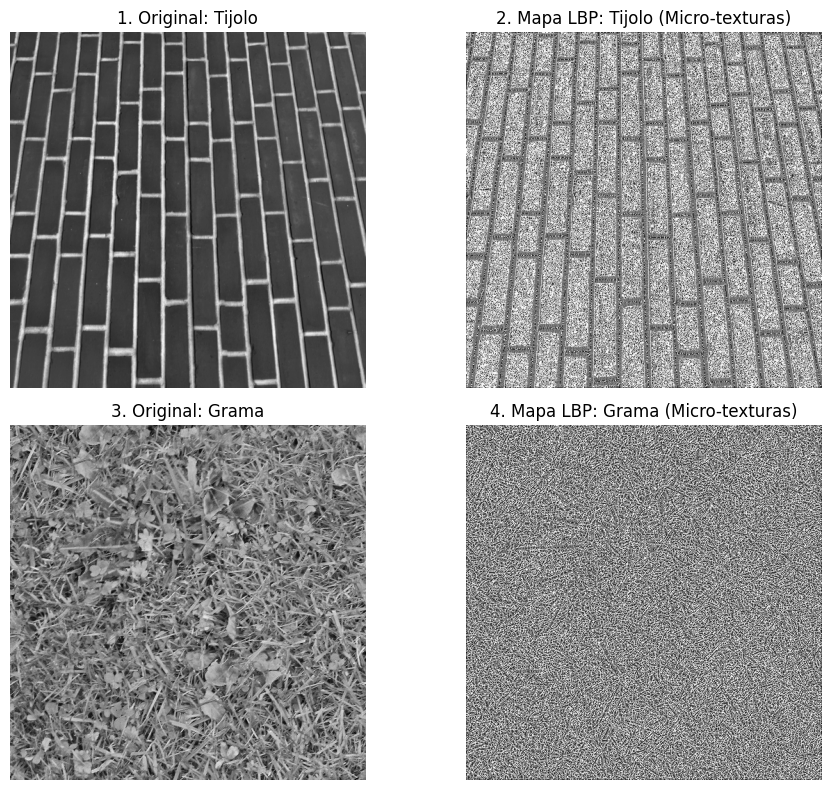

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, color
from skimage.feature import local_binary_pattern, graycomatrix, graycoprops

# Carregando imagens de textura clássicas
img_tijolo = data.brick() # Imagem em tons de cinza nativa
img_grama = data.grass()

#  Extração de Features com LBP (Textura Local)
# Parâmetros: radius (raio do círculo de vizinhos), n_points (quantos vizinhos olhar)
R = 1
P = 8 * R

# Aplicando o algoritmo
lbp_tijolo = local_binary_pattern(img_tijolo, P, R, method='uniform')
lbp_grama = local_binary_pattern(img_grama, P, R, method='uniform')

# Para o ML clássico (SVM/RF), nós extraímos o HISTOGRAMA do LBP, não a imagem!
# Isso cria um vetor unidimensional de contagens (nossas features)
hist_lbp_tijolo, _ = np.histogram(lbp_tijolo.ravel(), bins=np.arange(0, P + 3), density=True)
hist_lbp_grama, _ = np.histogram(lbp_grama.ravel(), bins=np.arange(0, P + 3), density=True)

# Extração de Features com GLCM (Estatística Global)
# Calculando a matriz considerando vizinhos a 1 pixel de distância, no ângulo de 0 radianos (horizontal)
glcm_tijolo = graycomatrix(img_tijolo, distances=[1], angles=[0], levels=256, symmetric=True, normed=True)
glcm_grama = graycomatrix(img_grama, distances=[1], angles=[0], levels=256, symmetric=True, normed=True)

# Extraindo as propriedades (Features tabulares prontas)
contraste_tijolo = graycoprops(glcm_tijolo, 'contrast')[0, 0]
energia_tijolo = graycoprops(glcm_tijolo, 'energy')[0, 0]

contraste_grama = graycoprops(glcm_grama, 'contrast')[0, 0]
energia_grama = graycoprops(glcm_grama, 'energy')[0, 0]


#Visualização
print("--- Features Tabulares GLCM Extraídas ---")
print(f"TIJOLO -> Contraste: {contraste_tijolo:.2f} | Energia: {energia_tijolo:.4f}")
print(f"GRAMA  -> Contraste: {contraste_grama:.2f} | Energia: {energia_grama:.4f}\n")
print("Observe como o contraste da grama (fios finos caóticos) é maior que o do tijolo")

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

axes[0, 0].imshow(img_tijolo, cmap='gray')
axes[0, 0].set_title("1. Original: Tijolo")
axes[0, 0].axis('off')

axes[0, 1].imshow(lbp_tijolo, cmap='gray')
axes[0, 1].set_title("2. Mapa LBP: Tijolo (Micro-texturas)")
axes[0, 1].axis('off')

axes[1, 0].imshow(img_grama, cmap='gray')
axes[1, 0].set_title("3. Original: Grama")
axes[1, 0].axis('off')

axes[1, 1].imshow(lbp_grama, cmap='gray')
axes[1, 1].set_title("4. Mapa LBP: Grama (Micro-texturas)")
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

Um pequeno Exemplo mostrando o emprego de diferentes recursos para criar um dataset apartir de imagens

In [ ]:
import numpy as np
from skimage import data, color, transform
from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# A Função de Engenharia de Recursos
def extrair_features(imagem_rgb):

    #Recebe uma imagem RGB, aplica HOG, LBP e GLCM, e concatena tudo
    #num único vetor unidimensional para o scikit-learn.

    # Padronização inicial: Redimensionar e converter para cinza, bem simples
    img_resized = transform.resize(imagem_rgb, (128, 128), anti_aliasing=True)

    #Se a imagem já for cinza, color.rgb2gray pode falhar, então fazemos uma checagem de segurança
    if len(img_resized.shape) == 3:
        img_cinza = color.rgb2gray(img_resized)
    else:
        img_cinza = img_resized

    # Como GLCM e LBP precisam de inteiros (0-255), convertemos a imagem
    img_cinza_int = (img_cinza * 255).astype(np.uint8)

    # Feature 1: HOG (Forma e Silhueta)
    vetor_hog = hog(img_cinza, orientations=8, pixels_per_cell=(16, 16),
                    cells_per_block=(1, 1), feature_vector=True)

    #  Feature 2: LBP (Micro-textura)
    raio = 1
    n_pontos = 8 * raio
    mapa_lbp = local_binary_pattern(img_cinza_int, n_pontos, raio, method='uniform')
    # Extraímos o histograma (frequência de cada padrão binário)
    vetor_lbp, _ = np.histogram(mapa_lbp.ravel(), bins=np.arange(0, n_pontos + 3), density=True)

    # Feature 3: GLCM (Estatística Macro)
    glcm = graycomatrix(img_cinza_int, distances=[1], angles=[0], levels=256, symmetric=True, normed=True)
    contraste = graycoprops(glcm, 'contrast')[0, 0]
    energia = graycoprops(glcm, 'energy')[0, 0]
    correlacao = graycoprops(glcm, 'correlation')[0, 0]

    # Colocamos os escalares da GLCM num pequeno array 1D
    vetor_glcm = np.array([contraste, energia, correlacao])

    # Concatenação Horizontal
    # Colamos os 3 vetores uns aos outros para formar a "Features" da imagem
    super_vetor = np.hstack([vetor_hog, vetor_lbp, vetor_glcm])

    return super_vetor

#  Montando o Dataset Tabular (Simulando Várias Imagens)
print("Extraindo features das imagens e montando a matriz X...")

# Usamos imagens nativas do skimage para o teste
X_lista = []
y_lista = []

# Simulando a Classe 0 (Texturas rústicas/Tijolo)
for i in range(10): # Gerando 10 variações do tijolo
    img_base = data.brick()
    img_variada = transform.rotate(img_base, angle=np.random.uniform(-10, 10))
    X_lista.append(extrair_features(img_variada))
    y_lista.append(0)

# Simulando a Classe 1 (Texturas orgânicas/Grama)
for i in range(10): # Gerando 10 variações da grama
    img_base = data.grass()
    img_variada = transform.rotate(img_base, angle=np.random.uniform(-10, 10))
    X_lista.append(extrair_features(img_variada))
    y_lista.append(1)

# Convertendo a lista para a matriz final NumPy (A nossa tabela relacional)
X = np.array(X_lista)
y = np.array(y_lista)

print(f"\nEstrutura Tabular Pronta para o scikit-learn")
print(f"Formato da Matriz X: {X.shape}")
print(f"Isto significa: {X.shape[0]} amostras e {X.shape[1]} colunas de features (HOG + LBP + GLCM)\n")

#  O Treinamento Clássico
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

#  Padronização é OBRIGATÓRIA
# O HOG gera números pequenos (0 a 1), mas o Contraste da GLCM pode gerar números na casa dos milhares.
# Sem o StandardScaler,
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

modelo_rf = RandomForestClassifier(n_estimators=50, random_state=42)
modelo_rf.fit(X_train_scaled, y_train)

y_pred = modelo_rf.predict(X_test_scaled)
print(f"Acurácia do Modelo: {accuracy_score(y_test, y_pred) * 100:.2f}%")

Extraindo features das imagens e montando a matriz X...

Estrutura Tabular Pronta para o scikit-learn
Formato da Matriz X: (20, 525)
Isto significa: 20 amostras e 525 colunas de features (HOG + LBP + GLCM)

Acurácia do Modelo: 100.00%


In [ ]:
import urllib.request
import tarfile
from pathlib import Path
import os

# Definição da fonte de dados (Data Ingestion)
url_dataset = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
arquivo_destino = "flower_photos.tgz"
diretorio_extracao = Path("/content/dataset_real")

# Criar o diretório raiz se não existir
diretorio_extracao.mkdir(parents=True, exist_ok=True)

caminho_arquivo_tgz = diretorio_extracao / arquivo_destino

#  Download Condicional
# O script verifica se o arquivo já existe para não baixar 220MB toda vez que rodar a célula
if not caminho_arquivo_tgz.exists():
    print("Iniciando o download do dataset real (220 MB)... Isso pode levar alguns segundos.")
    urllib.request.urlretrieve(url_dataset, caminho_arquivo_tgz)
    print("Download concluído!")
else:
    print("Arquivo compactado já detectado no cache local.")

#  Extração dos Arquivos
caminho_flower_photos = diretorio_extracao / "flower_photos"

if not caminho_flower_photos.exists():
    print("Extraindo os arquivos...")
    with tarfile.open(caminho_arquivo_tgz, "r:gz") as tar:
        tar.extractall(path=diretorio_extracao)
    print("Extração finalizada! Estrutura de diretórios montada.")
else:
    print("Arquivos já extraídos e prontos para uso.")

# 4. Inspeção da Estrutura Criada
print("\n--- Auditoria do Dataset ---")
for pasta_classe in caminho_flower_photos.iterdir():
    if pasta_classe.is_dir():
        num_imagens = len(list(pasta_classe.glob("*.jpg")))
        print(f"Classe '{pasta_classe.name}': {num_imagens} imagens encontradas.")

Iniciando o download do dataset real (220 MB)... Isso pode levar alguns segundos.
Download concluído!
Extraindo os arquivos...


/tmp/ipykernel_7672/1174903489.py:31: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=diretorio_extracao)


Extração finalizada! Estrutura de diretórios montada.

--- Auditoria do Dataset ---
Classe 'sunflowers': 699 imagens encontradas.
Classe 'roses': 641 imagens encontradas.
Classe 'tulips': 799 imagens encontradas.
Classe 'daisy': 633 imagens encontradas.
Classe 'dandelion': 898 imagens encontradas.


In [ ]:
# Apenas atualize estas duas variáveis no script anterior:
DIRETORIO_RAIZ = Path("/content/dataset_real/flower_photos")
CLASSES = ["roses", "sunflowers"] # usar uma parte

X_lista = []
y_lista = []

print("Iniciando a varredura do diretório e extração de features...")

for label_idx, nome_classe in enumerate(CLASSES):
    pasta_classe = DIRETORIO_RAIZ / nome_classe

    # Validação de infraestrutura: A pasta realmente existe?
    if not pasta_classe.exists():
        print(f"Aviso: O diretório {pasta_classe} não foi encontrado. Pule se for um teste.")
        continue

    print(f"Processando a classe: {nome_classe} (Label: {label_idx})")

    # iterdir() lista todos os arquivos dentro da pasta
    for caminho_arquivo in pasta_classe.iterdir():
        # Filtro de segurança para ler apenas imagens
        if caminho_arquivo.suffix.lower() not in ['.jpg', '.jpeg', '.png', '.tif']:
            continue

        try:
            # 1. Extração (Extract)
            imagem_bruta = io.imread(caminho_arquivo)

            # 2. Transformação (Transform)
            vetor_features = extrair_features(imagem_bruta)

            # 3. Carga (Load) na estrutura tabular
            X_lista.append(vetor_features)
            y_lista.append(label_idx)

        except Exception as e:
            # Em datasets reais, sempre haverá uma imagem corrompida ou vazia
            print(f"Erro ao processar {caminho_arquivo.name}: {e}")

# Convertendo a lista para matrizes NumPy
X = np.array(X_lista)
y = np.array(y_lista)

# Trava de segurança para se a pasta estiver vazia
if len(X) == 0:
    print("\nNenhuma imagem foi processada. Verifique os caminhos das pastas!")
else:
    print(f"\nMatriz X montada! Formato: {X.shape}")

    # O Treinamento Clássico
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    modelo_rf = RandomForestClassifier(n_estimators=50, random_state=42)
    modelo_rf.fit(X_train_scaled, y_train)

    y_pred = modelo_rf.predict(X_test_scaled)
    print(f"Acurácia do Modelo: {accuracy_score(y_test, y_pred) * 100:.2f}%")

Iniciando a varredura do diretório e extração de features...
Processando a classe: roses (Label: 0)
Processando a classe: sunflowers (Label: 1)

Matriz X montada! Formato: (1340, 525)
Acurácia do Modelo: 72.64%


### podemos abordar de forma diferente?

Cores- color.rgb2gray removeu as cores e estamos trabalhando com flores onde as cores tem um papel relevante.

Vamos usar o HSV:

Em vez de misturar vermelho, verde e azul, o HSV separa a informação visual em três canais completamente independentes:

**H (Hue / Matiz):** É a cor em si. Matematicamente, é representado como o ângulo de um círculo, variando de 0° a 360° (no OpenCV, isso é mapeado para 0 a 179 para caber em 8 bits).

Exemplo: Vermelho fica em 0°, Verde em 120°, e Azul em 240°.

**S (Saturation / Saturação)**: É a pureza ou "vivacidade" da cor, variando de 0 a 100%.

Exemplo: Uma saturação de 100% é a cor vibrante pura. Se você for diminuindo a saturação para 0%, a cor vai "desbotando" até se tornar um tom de cinza, independentemente de qual seja o Matiz.

**V (Value / Valor ou Brilho)**: É a intensidade da iluminação na cor, variando de 0 a 100%.

Exemplo: 0% é o breu total (preto absoluto). 100% é a cor totalmente iluminada.

A Maldição da Dimensionalidade - 525 features

Ruído de Fundo vs. Sinal- as flores tem fundo, onde boa parte da informação vai ser ruido. HOG vai pegar a  silueta do fundo tambem.

transform.resize(imagem, (128, 128)) - vai trazer deformação, temos que ajustar




In [ ]:
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from skimage import io, color, transform, filters
from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report


# PIPELINE DE PRÉ-PROCESSAMENTO (ETL)

def extrair_features_avancadas(imagem_rgb):
    # Center Crop
    h, w, _ = imagem_rgb.shape
    min_dim = min(h, w)
    start_y = (h - min_dim) // 2
    start_x = (w - min_dim) // 2
    img_crop = imagem_rgb[start_y:start_y+min_dim, start_x:start_x+min_dim]

    # Segmentação Otsu
    img_cinza_crop = color.rgb2gray(img_crop)
    limiar = filters.threshold_otsu(img_cinza_crop)
    mascara = img_cinza_crop > limiar

    img_mascarada = img_crop.copy()
    for i in range(3):
        img_mascarada[:, :, i] = img_mascarada[:, :, i] * mascara

    img_resized = transform.resize(img_crop, (128, 128), anti_aliasing=True)

    # HSV- traz cor
    img_hsv = color.rgb2hsv(img_resized)
    hist_hue, _ = np.histogram(img_hsv[:, :, 0], bins=16, range=(0, 1), density=True)
    hist_sat, _ = np.histogram(img_hsv[:, :, 1], bins=16, range=(0, 1), density=True)
    vetor_cor = np.hstack([hist_hue, hist_sat])

    # Features Clássicas
    img_cinza_resized = color.rgb2gray(img_resized)
    img_cinza_int = (img_cinza_resized * 255).astype(np.uint8)

    vetor_hog = hog(img_cinza_resized, orientations=8, pixels_per_cell=(16, 16),
                    cells_per_block=(1, 1), feature_vector=True)

    raio = 1
    n_pontos = 8 * raio
    mapa_lbp = local_binary_pattern(img_cinza_int, n_pontos, raio, method='uniform')
    vetor_lbp, _ = np.histogram(mapa_lbp.ravel(), bins=np.arange(0, n_pontos + 3), density=True)

    glcm = graycomatrix(img_cinza_int, distances=[1], angles=[0], levels=256, symmetric=True, normed=True)
    contraste = graycoprops(glcm, 'contrast')[0, 0]
    energia = graycoprops(glcm, 'energy')[0, 0]
    correlacao = graycoprops(glcm, 'correlation')[0, 0]
    vetor_glcm = np.array([contraste, energia, correlacao])

    return np.hstack([vetor_cor, vetor_hog, vetor_lbp, vetor_glcm])

#
#
DIRETORIO_RAIZ = Path("/content/dataset_real/flower_photos")

#  comentar/descomentar as classes que querem testar
CLASSES = [
   # "daisy",
    #"dandelion",
    "roses",
    "sunflowers",
    #"tulips"
]

print(f"Iniciando a extração para as classes: {CLASSES}")
print("Aviso: O processamento percorrerá todas as imagens sem limite. Isso levará tempo...")

X_lista, y_lista = [], []

for label_idx, nome_classe in enumerate(CLASSES):
    pasta = DIRETORIO_RAIZ / nome_classe

    # Trava de segurança caso  nome da classe errado
    if not pasta.exists():
        print(f"Aviso: O diretório '{pasta}' não foi encontrado. Ignorando...")
        continue

    imagens_processadas = 0
    # O loop processa todas as imagens disponíveis na pasta
    for caminho_arquivo in pasta.glob("*.jpg"):
        try:
            imagem_bruta = io.imread(caminho_arquivo)
            vetores = extrair_features_avancadas(imagem_bruta)
            X_lista.append(vetores)
            y_lista.append(label_idx) # O índice da lista CLASSES vira a tag numérica
            imagens_processadas += 1
        except Exception:
            continue

    print(f"[{nome_classe}] -> {imagens_processadas} imagens extraídas com sucesso.")

X = np.array(X_lista)
y = np.array(y_lista)
print(f"\nExtração concluída! Formato da Matriz X: {X.shape}")


#  MACHINE LEARNINGe REDUÇÃO DE DIMENSIONALIDADE

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=100, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"Formato da Matriz X pós-PCA: {X_train_pca.shape}\n")

# n_jobs=-1 garante que a CPU use todos os núcleos para treinar as árvores mais rápido
modelo_rf = RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1)
modelo_rf.fit(X_train_pca, y_train)

y_pred = modelo_rf.predict(X_test_pca)

print(f"Acurácia Global do Modelo: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Relatório Detalhado por Classe:")
# Passamos o array manual CLASSES para nomear as linhas do relatório
print(classification_report(y_test, y_pred, target_names=CLASSES))

Iniciando a extração para as classes: ['roses', 'sunflowers']
Aviso: O processamento percorrerá todas as imagens sem limite. Isso levará tempo...
[roses] -> 641 imagens extraídas com sucesso.
[sunflowers] -> 699 imagens extraídas com sucesso.

Extração concluída! Formato da Matriz X: (1340, 557)
Formato da Matriz X pós-PCA: (938, 100)

Acurácia Global do Modelo: 78.36%

Relatório Detalhado por Classe:
              precision    recall  f1-score   support

       roses       0.81      0.73      0.77       198
  sunflowers       0.76      0.84      0.80       204

    accuracy                           0.78       402
   macro avg       0.79      0.78      0.78       402
weighted avg       0.79      0.78      0.78       402



Para vermos o que alteramos na imagem

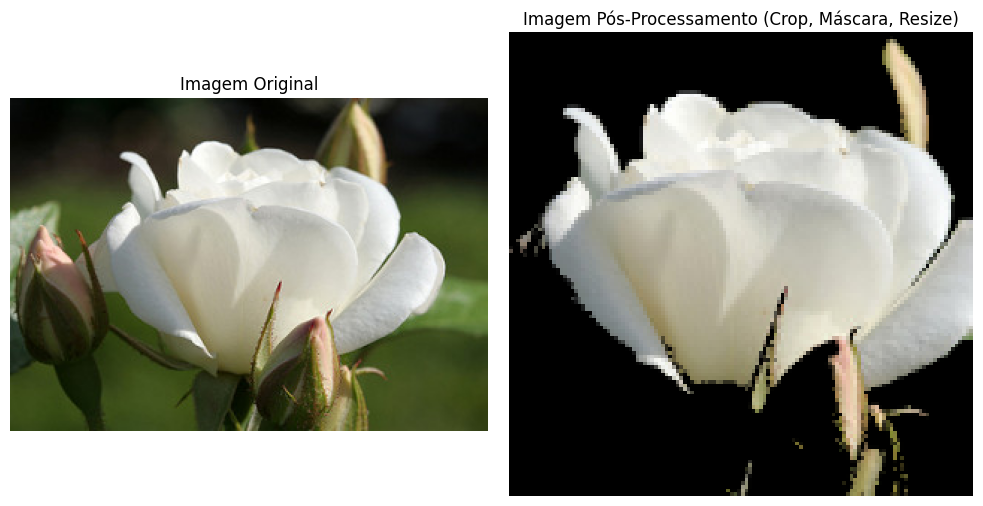

In [ ]:
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from skimage import io, color, transform, filters

# Selecionar uma imagem de exemplo
DIRETORIO_RAIZ = Path("/content/dataset_real/flower_photos")
# Vamos pegar a primeira imagem de rosa encontrada
example_image_path = list((DIRETORIO_RAIZ / "roses").glob("*.jpg"))[0]
imagem_original_uint8 = io.imread(example_image_path)

# Converter para float 0-1 para processamento consistente
imagem_original_float = imagem_original_uint8.astype(np.float32) / 255.0

# Aplicar etapas de pré-processamento para visualização ---

# Center Crop (corte central)
h, w, _ = imagem_original_float.shape
min_dim = min(h, w)
start_y = (h - min_dim) // 2
start_x = (w - min_dim) // 2
img_crop_float = imagem_original_float[start_y:start_y+min_dim, start_x:start_x+min_dim]

# Otsu Segmentation (segmentação Otsu na versão em tons de cinza da imagem cortada)
img_cinza_crop = color.rgb2gray(img_crop_float)
limiar = filters.threshold_otsu(img_cinza_crop)
mascara_bool = img_cinza_crop > limiar

# Aplicar a máscara à imagem colorida cortada
img_mascarada_float = img_crop_float * mascara_bool[:, :, np.newaxis]

# Resize para o tamanho alvo (128, 128)
img_processed_final = transform.resize(img_mascarada_float, (128, 128), anti_aliasing=True)

# Visualização das imagens
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(imagem_original_uint8) # Exibir imagem original uint8
axes[0].set_title("Imagem Original")
axes[0].axis('off')

axes[1].imshow(img_processed_final) # Exibir imagem processada float (matplotlib lida com float 0-1)
axes[1].set_title("Imagem Pós-Processamento (Crop, Máscara, Resize)")
axes[1].axis('off')

plt.tight_layout()
plt.show()